In [4]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

class PiecewiseLinearPolynomialsHex:
    def __init__(self, N_t, N_x, N_y, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, y_min=-1.0, y_max=1.0, gauss_order=3, bdry_order=3):
        """
        Initialize piecewise linear polynomials on a hexahedral mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            N_y: Number of divisions along the y-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: -1.0).
            x_max: Maximum value for x (default: 1.0).
            y_min: Minimum value for y (default: -1.0).
            y_max: Maximum value for y (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 3).
            bdry_order: Order of boundary quadrature (number of points per face direction, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.N_y = N_y
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.y_min = y_min
        self.y_max = y_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x * N_y  # Number of hexahedra
        self.partitions = self._generate_hexahedra()
        self.coeffs = jnp.zeros((self.N_elements, 4))  # Coefficients a + b*t + c*x + d*y per hexahedron
        self.quad_points, self.quad_weights, self.element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        # self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        # self.normals = self.compute_normals()

    def _generate_hexahedra(self):
        """Generate the hexahedra for the mesh with custom ranges."""
        self.tau = (self.t_max - self.t_min) / self.N_t
        self.hx = (self.x_max - self.x_min) / self.N_x
        self.hy = (self.y_max - self.y_min) / self.N_y
        t_starts = jnp.linspace(self.t_min, self.t_max - self.tau, self.N_t)
        x_starts = jnp.linspace(self.x_min, self.x_max - self.hx, self.N_x)
        y_starts = jnp.linspace(self.y_min, self.y_max - self.hy, self.N_y)
        tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
        # Define the 8 vertices for each hexahedron using binary offsets
        offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
        deltas = jnp.array([self.tau, self.hx, self.hy])
        offsets = offsets_bin * deltas  # (8,3)
        lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
        partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)
        return partitions
        
    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for hexahedral mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 3).
            quad_weights: Quadrature weights, shape (N_quad,).
            element_indices: Indices of hexahedra, shape (N_quad,).
            quad_points_parti: Quadrature points per hexahedron, shape (N_elements, Nq, 3).
            quad_weights_parti: Quadrature weights per hexahedron, shape (N_elements, Nq).
        """
        Nq = self.gauss_order ** 3  # Number of quadrature points per hexahedron

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 3D
        t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)
        t_weights, x_weights, y_weights = jnp.meshgrid(weights_jnp, weights_jnp, weights_jnp)
        quad_weights_3d = (t_weights * x_weights * y_weights).ravel()

        # Function to map [-1,1]^3 to hexahedron [t_low, t_high]x[x_low, x_high]x[y_low, y_high]
        def map_to_hex(hex):
            t_low, x_low, y_low = hex[0]
            t_high, x_high, y_high = hex[-1]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            y_scale = (y_high - y_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            y_center = (y_high + y_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            y_points = y_center + y_nodes.ravel() * y_scale
            points = jnp.stack([t_points, x_points, y_points], axis=1)
            weights = quad_weights_3d * (t_scale * x_scale * y_scale)
            return points, weights

        # Vectorize over hexahedra
        quad_points_parti, quad_weights_parti = vmap(map_to_hex)(self.partitions)

        # Flatten for global quadrature
        quad_points = quad_points_parti.reshape(-1, 3)
        quad_weights = quad_weights_parti.reshape(-1)
        element_indices = jnp.repeat(jnp.arange(self.N_elements), Nq)

        return quad_points, quad_weights, element_indices, quad_points_parti, quad_weights_parti


In [15]:
import jax.numpy as jnp
from jax import vmap
import numpy as np
from scipy.integrate import tplquad
import math

# Define a complicated test function (non-polynomial to stress the quadrature)
def test_function(t, x, y):
    return jnp.sin(2 * jnp.pi * t) * jnp.cos(3 * jnp.pi * x) * jnp.exp(y) + t * x**2 * y**3 + jnp.log(1 + jnp.abs(t + x + y))

# Vectorized version for JAX quadrature points
def test_function_vec(points):
    t, x, y = points[:, 0], points[:, 1], points[:, 2]
    return test_function(t, x, y)

# SciPy version (uses NumPy)
def test_function_scipy(y, x, t):  # Order for tplquad: integrand(y, x, t) with dy dx dt
    return np.sin(2 * np.pi * t) * np.cos(3 * np.pi * x) * np.exp(y) + t * x**2 * y**3 + np.log(1 + np.abs(t + x + y))

# Function to compute quadrature integral
def compute_quadrature_integral(plph):
    return jnp.sum(test_function_vec(plph.quad_points) * plph.quad_weights)

# Function to compute SciPy integral (high accuracy)
def compute_scipy_integral(t_min, t_max, x_min, x_max, y_min, y_max):
    integral, error = tplquad(
        test_function_scipy,
        t_min, t_max,  # dt
        lambda t: x_min, lambda t: x_max,  # dx
        lambda t, x: y_min, lambda t, x: y_max,  # dy
        epsabs=1e-10, epsrel=1e-10
    )
    return integral, error

# Basic check: sum of weights should equal domain volume
def check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max):
    computed_volume = jnp.sum(plph.quad_weights)
    exact_volume = (t_max - t_min) * (x_max - x_min) * (y_max - y_min)
    print(f"Computed volume: {computed_volume}, Exact volume: {exact_volume}")
    return abs(computed_volume - exact_volume) < 1e-10

# Test with specific parameters
N_t, N_x, N_y = 3, 3, 3  # Small number of divisions for testing
t_min, t_max = 0.0, 1.0
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
gauss_order = 5  # Default

plph = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min, t_max, x_min, x_max, y_min, y_max, gauss_order)

# Check volume
volume_check = check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max)
print(f"Volume check passed: {volume_check}")

# Compute integrals
quad_int = compute_quadrature_integral(plph)
# scipy_int, scipy_error = compute_scipy_integral(t_min, t_max, x_min, x_max, y_min, y_max)

print(f"Quadrature integral: {quad_int}")
print(f"SciPy integral: {scipy_int} (estimated error: {scipy_error})")

# Compare (difference should be small, depending on gauss_order and mesh refinement)
difference = abs(quad_int - scipy_int)
print(f"Absolute difference: {difference}")
print(f"Relative difference: {difference / abs(scipy_int) if scipy_int != 0 else 'N/A'}")

# To further test correctness, you can increase gauss_order, N_t, N_x, N_y and observe convergence to SciPy value.2.9s

Computed volume: 4.0, Exact volume: 4.0
Volume check passed: True
Quadrature integral: 2.181187391281128
SciPy integral: 2.181217770752753 (estimated error: 5.273749182494284e-07)
Absolute difference: 3.0279159545898438e-05
Relative difference: 1.3881768609280698e-05


In [12]:
# Test with specific parameters
N_t, N_x, N_y = 3, 3, 3  # Small number of divisions for testing
t_min, t_max = 0.0, 1.0
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
gauss_order = 3  # Default

plph = PiecewiseLinearPolynomialsHex(N_t, N_x, N_y, t_min, t_max, x_min, x_max, y_min, y_max, gauss_order)

# Check volume
volume_check = check_volume(plph, t_min, t_max, x_min, x_max, y_min, y_max)
print(f"Volume check passed: {volume_check}")

# Compute integrals
quad_int = compute_quadrature_integral(plph)

Computed volume: 3.999999761581421, Exact volume: 4.0
Volume check passed: False


In [16]:
plph.quad_weights.shape

(3375,)

In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta

In [2]:
def u0(x):
    return (-jnp.sign(x) + 1)*2

# Boundary at x=-1
def u1(x):
    return 4
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

def u_ref(t, x):
    return u0(x-2*t)

t_min = 0
t_max = 0.5
x_min = -0.5
x_max = 1.5


In [3]:
N_t = 8
N_x = 8
seq_trainer = SeqMinMaxOptProb(
    input_dim=2, num_segments=3,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0, pre_epochs=0,
    sigma=5, N_perturb=20000, k_h_rf_times=2, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="minmax_burgers_strong_moving_shock",
    gamma=0, N_test_gamma=1000, adjust_gamma=False, lambda_ic=10, lambda_bc=10, lambda_eqn=1,
    L1reg=0, sampling_method='uniform', notes='', 
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=1000, partition='tri', 
    set_wandb=False
)


Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.299298, lambda_bc: 9.558501, lambda_eqn: 1.105409
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
Grade 0, Iter 0, loss_eqn: 1.832606, loss_eqn_from_kh: 1.832308, loss_l1: 1.832308, loss_ibc: 20.663330


C:\Users\hao6li\Projects\NN-HCL\Code\my_helpers.py:156: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


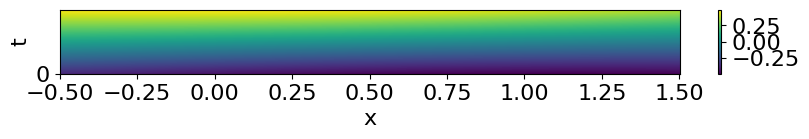

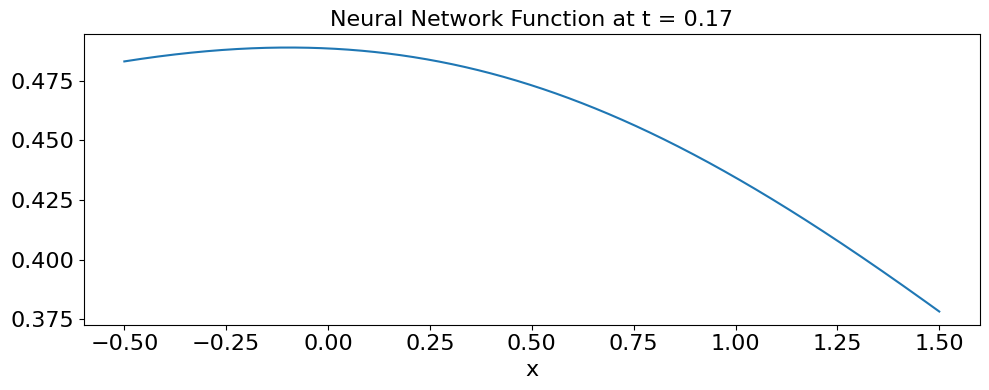

Grade 0, Iter 100, loss_eqn: 1.415782, loss_eqn_from_kh: 1.446013, loss_l1: 1.447376, loss_ibc: 1.598279
Grade 0, Iter 200, loss_eqn: 1.572702, loss_eqn_from_kh: 1.530046, loss_l1: 1.548249, loss_ibc: 0.306427
Grade 0, Iter 300, loss_eqn: 0.566192, loss_eqn_from_kh: 0.561840, loss_l1: 0.868931, loss_ibc: 0.096510
Grade 0, Iter 400, loss_eqn: 0.362952, loss_eqn_from_kh: 0.359998, loss_l1: 0.783377, loss_ibc: 0.048048
Grade 0, Iter 500, loss_eqn: 0.319870, loss_eqn_from_kh: 0.327488, loss_l1: 0.740508, loss_ibc: 0.039315
Grade 0, Iter 600, loss_eqn: 0.335891, loss_eqn_from_kh: 0.341802, loss_l1: 0.745245, loss_ibc: 0.032696
Grade 0, Iter 700, loss_eqn: 0.327413, loss_eqn_from_kh: 0.330761, loss_l1: 0.744008, loss_ibc: 0.028546
Grade 0, Iter 800, loss_eqn: 0.329463, loss_eqn_from_kh: 0.325218, loss_l1: 0.729997, loss_ibc: 0.026757
Grade 0, Iter 900, loss_eqn: 0.326766, loss_eqn_from_kh: 0.327751, loss_l1: 0.738644, loss_ibc: 0.022198
Grade 0, Iter 1000, lambda_ic: 12.339686, lambda_bc: 9.

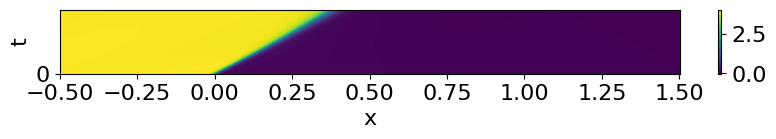

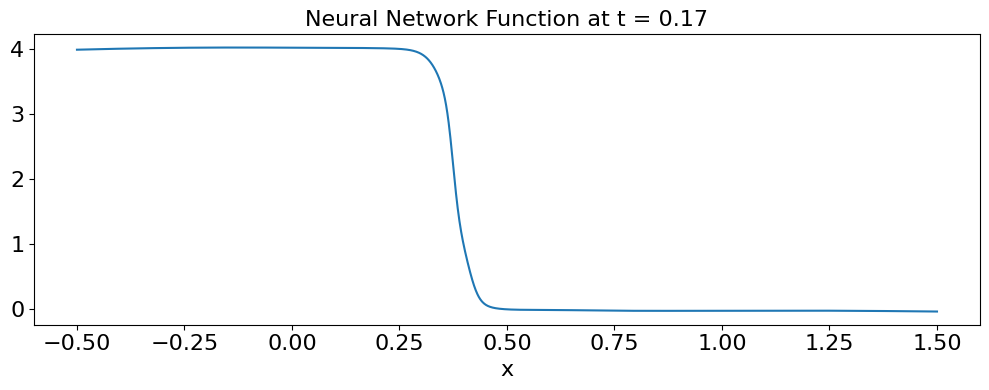

Grade 0, Iter 1100, loss_eqn: 0.314549, loss_eqn_from_kh: 0.305460, loss_l1: 0.691563, loss_ibc: 0.015902
Grade 0, Iter 1200, loss_eqn: 0.282299, loss_eqn_from_kh: 0.278511, loss_l1: 0.712710, loss_ibc: 0.013060
Grade 0, Iter 1300, loss_eqn: 0.227471, loss_eqn_from_kh: 0.309106, loss_l1: 0.799952, loss_ibc: 0.012820
Grade 0, Iter 1400, loss_eqn: 0.208846, loss_eqn_from_kh: 0.208733, loss_l1: 0.677517, loss_ibc: 0.011262
Grade 0, Iter 1500, loss_eqn: 0.205375, loss_eqn_from_kh: 0.187672, loss_l1: 0.678327, loss_ibc: 0.011205
Grade 0, Iter 1600, loss_eqn: 0.206165, loss_eqn_from_kh: 0.187056, loss_l1: 0.682936, loss_ibc: 0.012154
Grade 0, Iter 1700, loss_eqn: 0.176221, loss_eqn_from_kh: 0.240391, loss_l1: 0.671253, loss_ibc: 0.009775
Grade 0, Iter 1800, loss_eqn: 0.207520, loss_eqn_from_kh: 0.155312, loss_l1: 0.627882, loss_ibc: 0.013387
Grade 0, Iter 1900, loss_eqn: 0.139193, loss_eqn_from_kh: 0.158884, loss_l1: 0.629639, loss_ibc: 0.009177
Grade 0, Iter 2000, lambda_ic: 16.415932, lamb

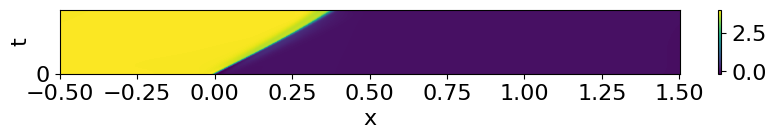

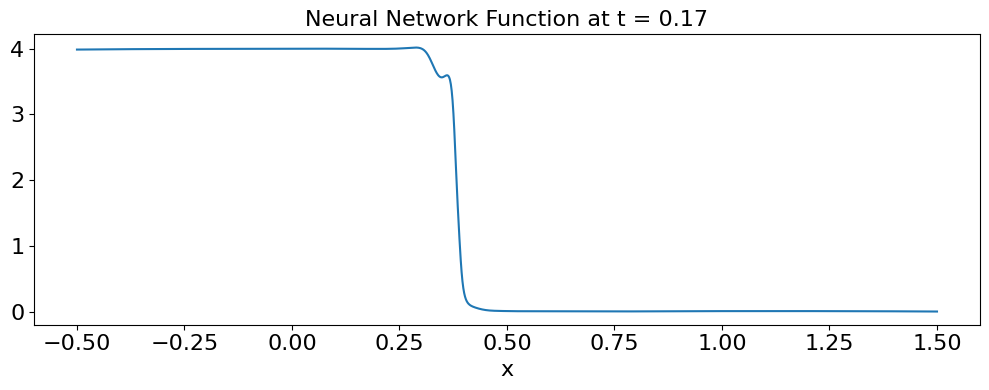

Grade 0, Iter 2100, loss_eqn: 0.128295, loss_eqn_from_kh: 0.123006, loss_l1: 0.575675, loss_ibc: 0.008997
Grade 0, Iter 2200, loss_eqn: 0.136801, loss_eqn_from_kh: 0.106427, loss_l1: 0.547580, loss_ibc: 0.008263
Grade 0, Iter 2300, loss_eqn: 0.144975, loss_eqn_from_kh: 0.120798, loss_l1: 0.561477, loss_ibc: 0.010138
Grade 0, Iter 2400, loss_eqn: 0.138336, loss_eqn_from_kh: 0.126055, loss_l1: 0.561904, loss_ibc: 0.010457
Grade 0, Iter 2500, loss_eqn: 0.092124, loss_eqn_from_kh: 0.079695, loss_l1: 0.519034, loss_ibc: 0.007210
Grade 0, Iter 2600, loss_eqn: 0.141527, loss_eqn_from_kh: 0.087734, loss_l1: 0.539905, loss_ibc: 0.008264
Grade 0, Iter 2700, loss_eqn: 0.090926, loss_eqn_from_kh: 0.075551, loss_l1: 0.521514, loss_ibc: 0.008045
Grade 0, Iter 2800, loss_eqn: 0.102975, loss_eqn_from_kh: 0.097229, loss_l1: 0.507738, loss_ibc: 0.006933
Grade 0, Iter 2900, loss_eqn: 0.100769, loss_eqn_from_kh: 0.114289, loss_l1: 0.532735, loss_ibc: 0.008401
Grade 0, Iter 3000, lambda_ic: 17.414787, lamb

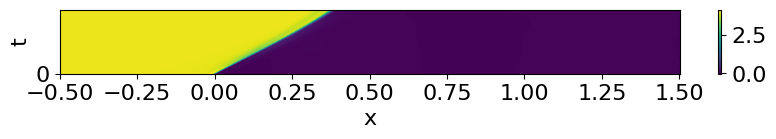

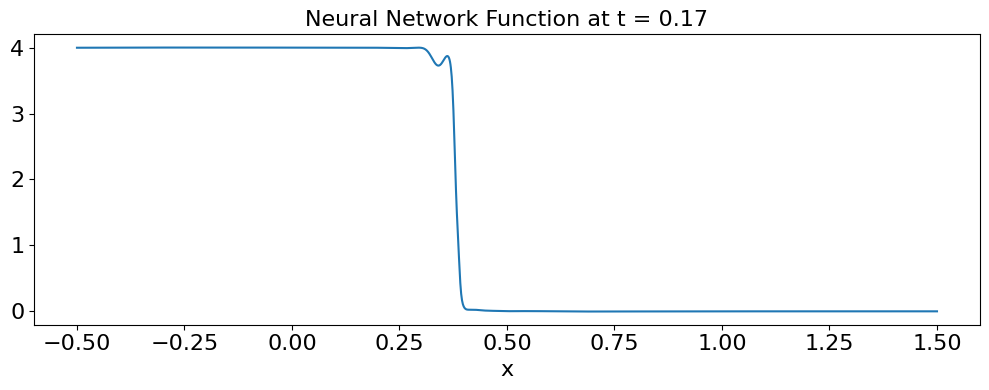

Grade 0, Iter 3100, loss_eqn: 0.063324, loss_eqn_from_kh: 0.070832, loss_l1: 0.471252, loss_ibc: 0.006838
Grade 0, Iter 3200, loss_eqn: 0.095575, loss_eqn_from_kh: 0.065450, loss_l1: 0.466068, loss_ibc: 0.006464
Grade 0, Iter 3300, loss_eqn: 0.075651, loss_eqn_from_kh: 0.065979, loss_l1: 0.460622, loss_ibc: 0.006246
Grade 0, Iter 3400, loss_eqn: 0.080778, loss_eqn_from_kh: 0.067744, loss_l1: 0.448521, loss_ibc: 0.006133
Grade 0, Iter 3500, loss_eqn: 0.066247, loss_eqn_from_kh: 0.056468, loss_l1: 0.467569, loss_ibc: 0.006636
Grade 0, Iter 3600, loss_eqn: 0.062766, loss_eqn_from_kh: 0.049691, loss_l1: 0.461042, loss_ibc: 0.006512
Grade 0, Iter 3700, loss_eqn: 0.047995, loss_eqn_from_kh: 0.059343, loss_l1: 0.436850, loss_ibc: 0.005808
Grade 0, Iter 3800, loss_eqn: 0.044533, loss_eqn_from_kh: 0.055053, loss_l1: 0.463817, loss_ibc: 0.005738
Grade 0, Iter 3900, loss_eqn: 0.059225, loss_eqn_from_kh: 0.067312, loss_l1: 0.438977, loss_ibc: 0.006106
Grade 0, Iter 4000, lambda_ic: 39.579750, lamb

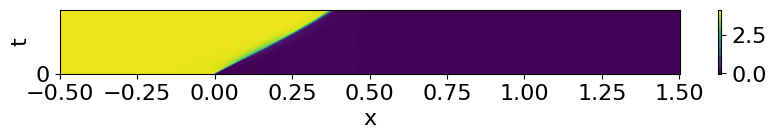

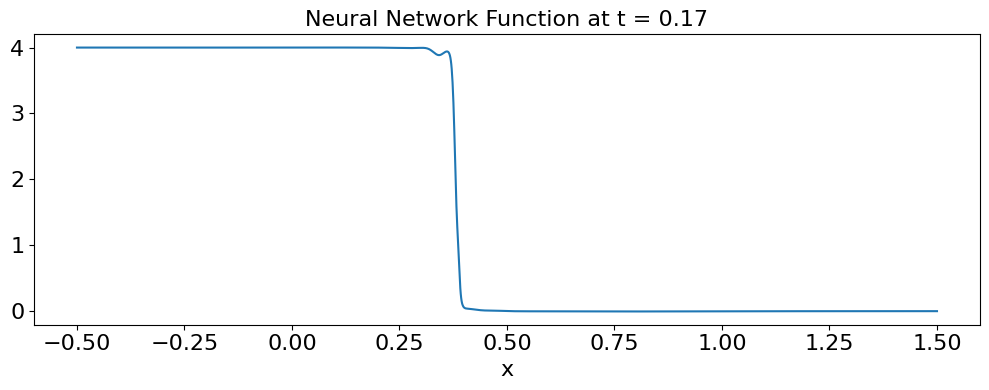

Grade 0, Iter 4100, loss_eqn: 0.043880, loss_eqn_from_kh: 0.046330, loss_l1: 0.441975, loss_ibc: 0.005026
Grade 0, Iter 4200, loss_eqn: 0.050731, loss_eqn_from_kh: 0.068160, loss_l1: 0.480494, loss_ibc: 0.005019
Grade 0, Iter 4300, loss_eqn: 0.059122, loss_eqn_from_kh: 0.054697, loss_l1: 0.469709, loss_ibc: 0.004516
Grade 0, Iter 4400, loss_eqn: 0.054994, loss_eqn_from_kh: 0.043080, loss_l1: 0.454495, loss_ibc: 0.004425
Grade 0, Iter 4500, loss_eqn: 0.049084, loss_eqn_from_kh: 0.043185, loss_l1: 0.456311, loss_ibc: 0.004380
Grade 0, Iter 4600, loss_eqn: 0.042262, loss_eqn_from_kh: 0.041998, loss_l1: 0.453012, loss_ibc: 0.004437
Grade 0, Iter 4700, loss_eqn: 0.041712, loss_eqn_from_kh: 0.041899, loss_l1: 0.455410, loss_ibc: 0.004365
Grade 0, Iter 4800, loss_eqn: 0.045897, loss_eqn_from_kh: 0.044764, loss_l1: 0.461474, loss_ibc: 0.004259
Grade 0, Iter 4900, loss_eqn: 0.041893, loss_eqn_from_kh: 0.041574, loss_l1: 0.454184, loss_ibc: 0.004301
Train time for stage1: 2081.144518 seconds

Pl

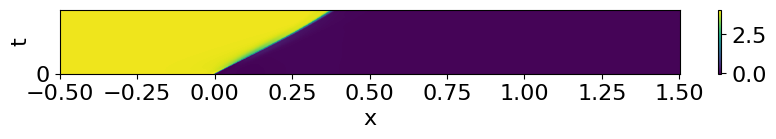

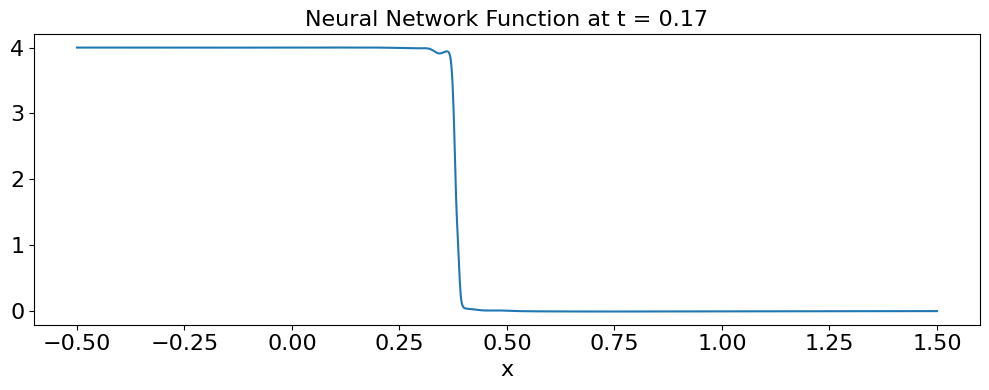

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.1667, 0.3333]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.227160, lambda_bc: 9.664361, lambda_eqn: 1.144342
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
Grade 0, Iter 0, loss_eqn: 1.832606, loss_eqn_from_kh: 1.832174, loss_l1: 1.832174, loss_ibc: 24.350309


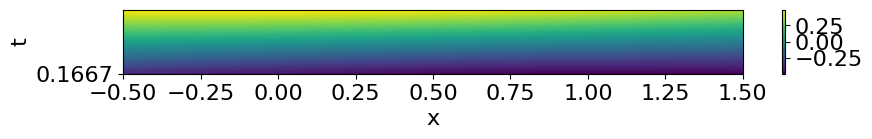

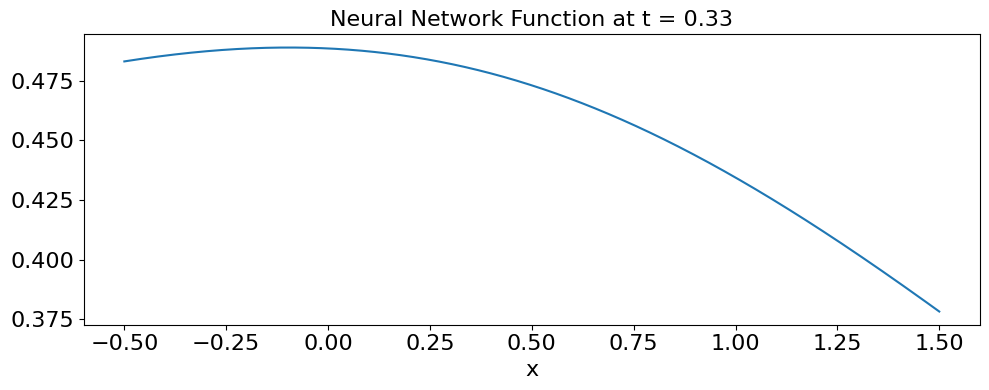

Grade 0, Iter 100, loss_eqn: 0.813892, loss_eqn_from_kh: 0.816309, loss_l1: 0.816626, loss_ibc: 1.222296
Grade 0, Iter 200, loss_eqn: 1.311515, loss_eqn_from_kh: 1.312047, loss_l1: 1.313445, loss_ibc: 0.886317
Grade 0, Iter 300, loss_eqn: 0.688921, loss_eqn_from_kh: 0.686432, loss_l1: 0.854795, loss_ibc: 0.153374
Grade 0, Iter 400, loss_eqn: 0.382158, loss_eqn_from_kh: 0.380317, loss_l1: 0.763379, loss_ibc: 0.042149
Grade 0, Iter 500, loss_eqn: 0.306001, loss_eqn_from_kh: 0.304859, loss_l1: 0.749155, loss_ibc: 0.020929
Grade 0, Iter 600, loss_eqn: 0.294756, loss_eqn_from_kh: 0.290295, loss_l1: 0.718227, loss_ibc: 0.018977
Grade 0, Iter 700, loss_eqn: 0.276859, loss_eqn_from_kh: 0.277822, loss_l1: 0.702439, loss_ibc: 0.017870
Grade 0, Iter 800, loss_eqn: 0.289588, loss_eqn_from_kh: 0.293663, loss_l1: 0.714343, loss_ibc: 0.016598
Grade 0, Iter 900, loss_eqn: 0.283114, loss_eqn_from_kh: 0.274504, loss_l1: 0.685841, loss_ibc: 0.016738
Grade 0, Iter 1000, lambda_ic: 9.328542, lambda_bc: 11.

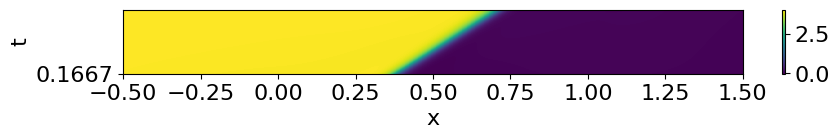

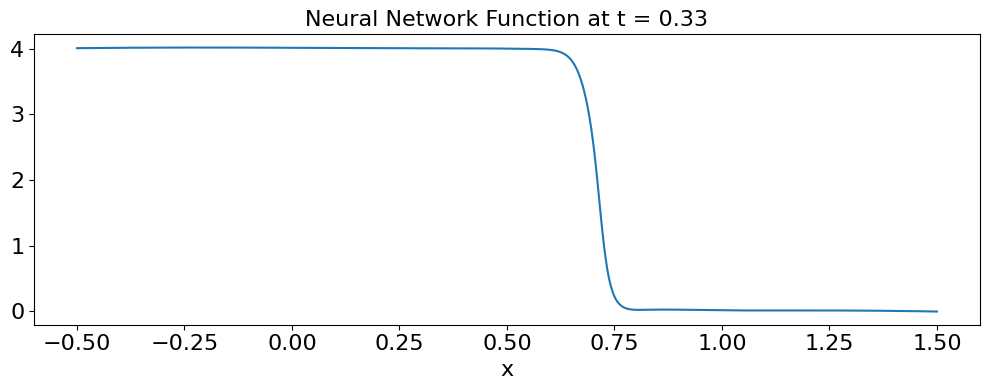

Grade 0, Iter 1100, loss_eqn: 0.298483, loss_eqn_from_kh: 0.310756, loss_l1: 0.736885, loss_ibc: 0.013629
Grade 0, Iter 1200, loss_eqn: 0.292491, loss_eqn_from_kh: 0.300661, loss_l1: 0.725327, loss_ibc: 0.012446
Grade 0, Iter 1300, loss_eqn: 0.289903, loss_eqn_from_kh: 0.303054, loss_l1: 0.725715, loss_ibc: 0.011072
Grade 0, Iter 1400, loss_eqn: 0.294164, loss_eqn_from_kh: 0.301358, loss_l1: 0.729933, loss_ibc: 0.010651
Grade 0, Iter 1500, loss_eqn: 0.287870, loss_eqn_from_kh: 0.281120, loss_l1: 0.709238, loss_ibc: 0.009980
Grade 0, Iter 1600, loss_eqn: 0.271727, loss_eqn_from_kh: 0.271398, loss_l1: 0.707999, loss_ibc: 0.013174
Grade 0, Iter 1700, loss_eqn: 0.263929, loss_eqn_from_kh: 0.278611, loss_l1: 0.701770, loss_ibc: 0.009772
Grade 0, Iter 1800, loss_eqn: 0.244935, loss_eqn_from_kh: 0.243612, loss_l1: 0.662782, loss_ibc: 0.007493
Grade 0, Iter 1900, loss_eqn: 0.218094, loss_eqn_from_kh: 0.221933, loss_l1: 0.636054, loss_ibc: 0.006731
Grade 0, Iter 2000, lambda_ic: 9.680532, lambd

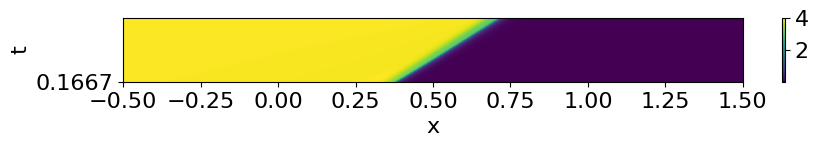

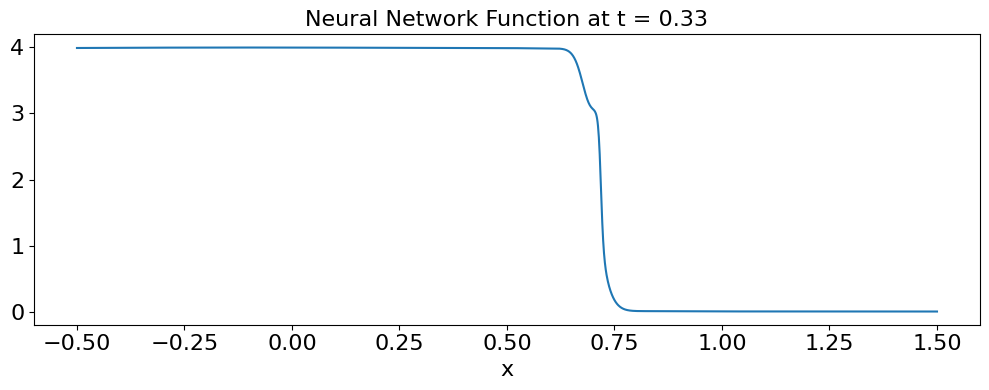

Grade 0, Iter 2100, loss_eqn: 0.205191, loss_eqn_from_kh: 0.223565, loss_l1: 0.620057, loss_ibc: 0.004547
Grade 0, Iter 2200, loss_eqn: 0.169453, loss_eqn_from_kh: 0.187095, loss_l1: 0.568262, loss_ibc: 0.002559
Grade 0, Iter 2300, loss_eqn: 0.219925, loss_eqn_from_kh: 0.185668, loss_l1: 0.578037, loss_ibc: 0.002013
Grade 0, Iter 2400, loss_eqn: 0.197015, loss_eqn_from_kh: 0.189411, loss_l1: 0.740175, loss_ibc: 0.002621
Grade 0, Iter 2500, loss_eqn: 0.190427, loss_eqn_from_kh: 0.181078, loss_l1: 0.746602, loss_ibc: 0.003040
Grade 0, Iter 2600, loss_eqn: 0.187748, loss_eqn_from_kh: 0.179880, loss_l1: 0.739555, loss_ibc: 0.001225
Grade 0, Iter 2700, loss_eqn: 0.174412, loss_eqn_from_kh: 0.175997, loss_l1: 0.756024, loss_ibc: 0.001538
Grade 0, Iter 2800, loss_eqn: 0.170023, loss_eqn_from_kh: 0.167521, loss_l1: 0.733789, loss_ibc: 0.001619
Grade 0, Iter 2900, loss_eqn: 0.161544, loss_eqn_from_kh: 0.160624, loss_l1: 0.712876, loss_ibc: 0.001619
Grade 0, Iter 3000, lambda_ic: 10.990685, lamb

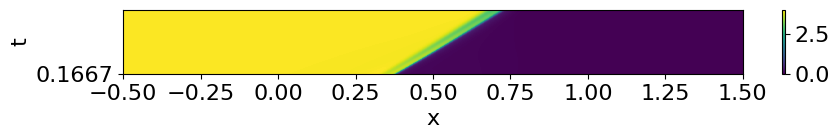

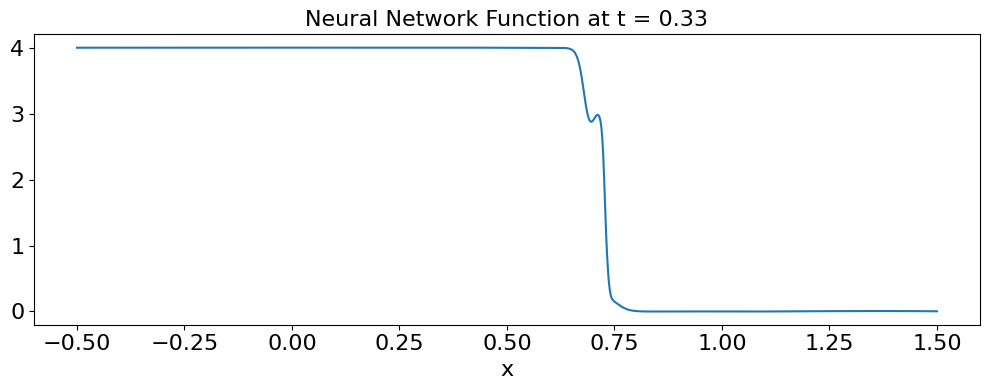

Grade 0, Iter 3100, loss_eqn: 0.152405, loss_eqn_from_kh: 0.156545, loss_l1: 0.712542, loss_ibc: 0.001474
Grade 0, Iter 3200, loss_eqn: 0.150143, loss_eqn_from_kh: 0.151652, loss_l1: 0.705251, loss_ibc: 0.001195
Grade 0, Iter 3300, loss_eqn: 0.145795, loss_eqn_from_kh: 0.146998, loss_l1: 0.701156, loss_ibc: 0.001170
Grade 0, Iter 3400, loss_eqn: 0.161674, loss_eqn_from_kh: 0.153488, loss_l1: 0.704118, loss_ibc: 0.001301
Grade 0, Iter 3500, loss_eqn: 0.148284, loss_eqn_from_kh: 0.153667, loss_l1: 0.706403, loss_ibc: 0.001292
Grade 0, Iter 3600, loss_eqn: 0.160069, loss_eqn_from_kh: 0.172189, loss_l1: 0.721445, loss_ibc: 0.001433
Grade 0, Iter 3700, loss_eqn: 0.142303, loss_eqn_from_kh: 0.142627, loss_l1: 0.689044, loss_ibc: 0.001197
Grade 0, Iter 3800, loss_eqn: 0.141258, loss_eqn_from_kh: 0.139001, loss_l1: 0.681553, loss_ibc: 0.001259
Grade 0, Iter 3900, loss_eqn: 0.137923, loss_eqn_from_kh: 0.138150, loss_l1: 0.682120, loss_ibc: 0.001208
Grade 0, Iter 4000, lambda_ic: 12.572776, lamb

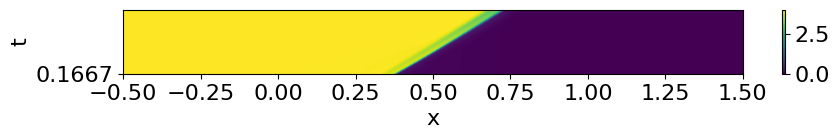

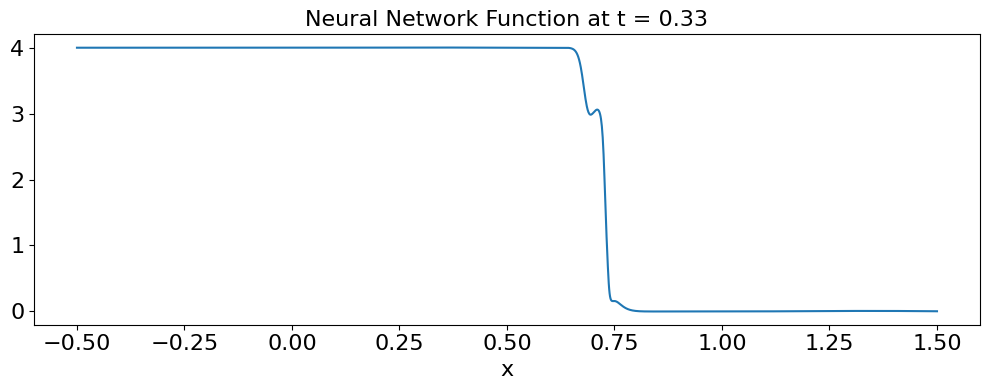

Grade 0, Iter 4100, loss_eqn: 0.133641, loss_eqn_from_kh: 0.132705, loss_l1: 0.670605, loss_ibc: 0.001137
Grade 0, Iter 4200, loss_eqn: 0.130299, loss_eqn_from_kh: 0.130165, loss_l1: 0.672280, loss_ibc: 0.001118
Grade 0, Iter 4300, loss_eqn: 0.128373, loss_eqn_from_kh: 0.127635, loss_l1: 0.667907, loss_ibc: 0.001156
Grade 0, Iter 4400, loss_eqn: 0.126299, loss_eqn_from_kh: 0.126400, loss_l1: 0.667338, loss_ibc: 0.001148
Grade 0, Iter 4500, loss_eqn: 0.126432, loss_eqn_from_kh: 0.125036, loss_l1: 0.664472, loss_ibc: 0.001119
Grade 0, Iter 4600, loss_eqn: 0.123729, loss_eqn_from_kh: 0.123777, loss_l1: 0.661827, loss_ibc: 0.001142
Grade 0, Iter 4700, loss_eqn: 0.122841, loss_eqn_from_kh: 0.123877, loss_l1: 0.664727, loss_ibc: 0.001140
Grade 0, Iter 4800, loss_eqn: 0.122224, loss_eqn_from_kh: 0.122171, loss_l1: 0.661256, loss_ibc: 0.001146
Grade 0, Iter 4900, loss_eqn: 0.121846, loss_eqn_from_kh: 0.121747, loss_l1: 0.661622, loss_ibc: 0.001145
Train time for stage1: 2105.725216 seconds

Pl

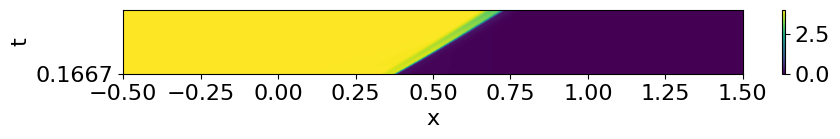

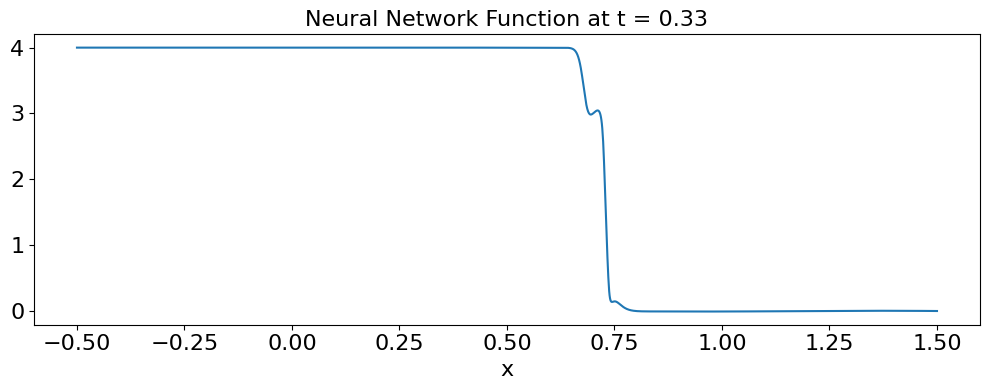

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.3333, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
The largest W^{1,inf} norm of k_h coeffs is 3.176214
Grade 0, Iter 0, lambda_ic: 9.195255, lambda_bc: 9.762321, lambda_eqn: 1.180370
p_coeffs_all.shape: (20000, 3), quad_points.shape: (48, 2)
Traced<float32[]>with<BatchTrace> with
  val = Traced<float32[128]>with<DynamicJaxprTrace>
  batch_dim = 0
Grade 0, Iter 0, loss_eqn: 1.832606, loss_eqn_from_kh: 1.832070, loss_l1: 1.832070, loss_ibc: 27.620842


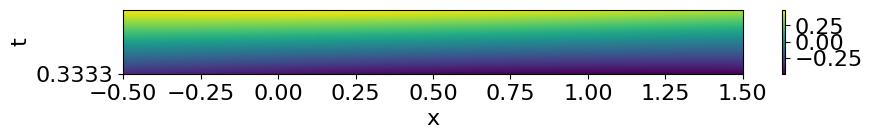

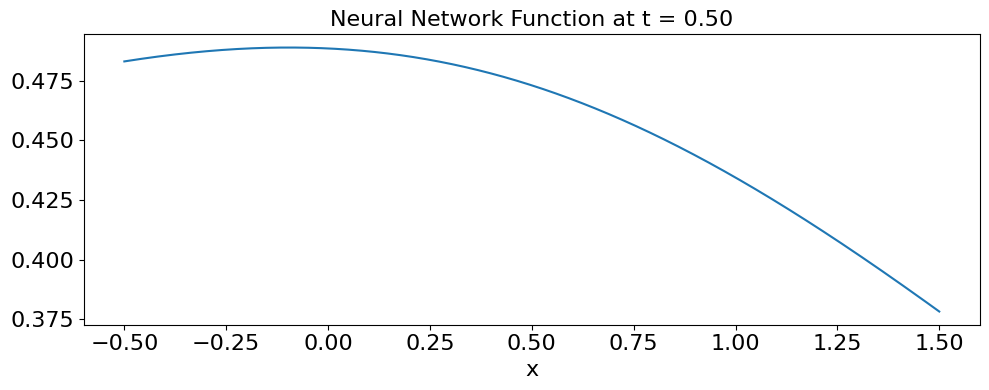

Grade 0, Iter 100, loss_eqn: 1.062888, loss_eqn_from_kh: 1.048718, loss_l1: 1.048772, loss_ibc: 0.982618
Grade 0, Iter 200, loss_eqn: 0.763746, loss_eqn_from_kh: 0.765547, loss_l1: 0.791885, loss_ibc: 0.477990
Grade 0, Iter 300, loss_eqn: 0.792937, loss_eqn_from_kh: 0.789376, loss_l1: 0.891251, loss_ibc: 0.121979
Grade 0, Iter 400, loss_eqn: 0.461830, loss_eqn_from_kh: 0.459662, loss_l1: 0.740732, loss_ibc: 0.028536
Grade 0, Iter 500, loss_eqn: 0.300537, loss_eqn_from_kh: 0.298996, loss_l1: 0.688790, loss_ibc: 0.013972
Grade 0, Iter 600, loss_eqn: 0.258696, loss_eqn_from_kh: 0.276175, loss_l1: 0.687785, loss_ibc: 0.011524
Grade 0, Iter 700, loss_eqn: 0.253097, loss_eqn_from_kh: 0.251248, loss_l1: 0.671150, loss_ibc: 0.010526
Grade 0, Iter 800, loss_eqn: 0.248445, loss_eqn_from_kh: 0.248834, loss_l1: 0.667620, loss_ibc: 0.012886
Grade 0, Iter 900, loss_eqn: 0.249648, loss_eqn_from_kh: 0.254778, loss_l1: 0.680401, loss_ibc: 0.009731
Grade 0, Iter 1000, lambda_ic: 9.330432, lambda_bc: 10.

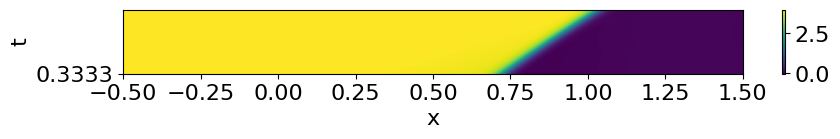

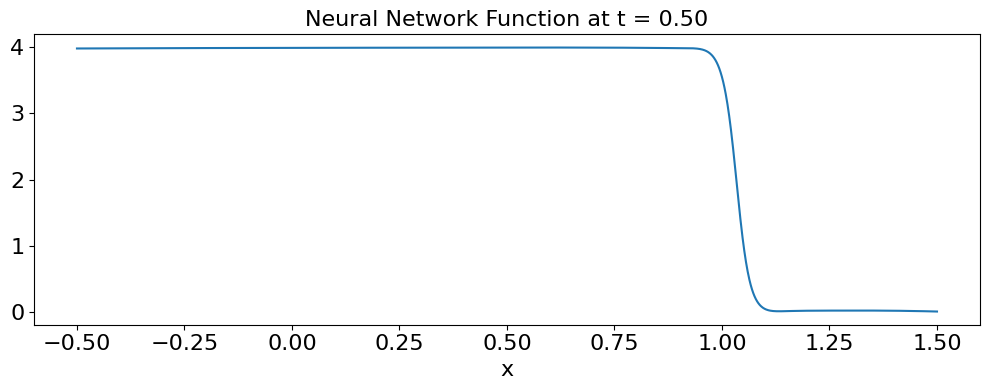

Grade 0, Iter 1100, loss_eqn: 0.231292, loss_eqn_from_kh: 0.236221, loss_l1: 0.665596, loss_ibc: 0.009296
Grade 0, Iter 1200, loss_eqn: 0.240984, loss_eqn_from_kh: 0.232651, loss_l1: 0.665247, loss_ibc: 0.010169
Grade 0, Iter 1300, loss_eqn: 0.252133, loss_eqn_from_kh: 0.242865, loss_l1: 0.669123, loss_ibc: 0.009151
Grade 0, Iter 1400, loss_eqn: 0.247754, loss_eqn_from_kh: 0.240918, loss_l1: 0.671358, loss_ibc: 0.008879
Grade 0, Iter 1500, loss_eqn: 0.246966, loss_eqn_from_kh: 0.243944, loss_l1: 0.666616, loss_ibc: 0.008681
Grade 0, Iter 1600, loss_eqn: 0.242990, loss_eqn_from_kh: 0.234145, loss_l1: 0.667853, loss_ibc: 0.008852
Grade 0, Iter 1700, loss_eqn: 0.251633, loss_eqn_from_kh: 0.264081, loss_l1: 0.676580, loss_ibc: 0.009205
Grade 0, Iter 1800, loss_eqn: 0.230987, loss_eqn_from_kh: 0.224665, loss_l1: 0.658101, loss_ibc: 0.008316
Grade 0, Iter 1900, loss_eqn: 0.228071, loss_eqn_from_kh: 0.228386, loss_l1: 0.658509, loss_ibc: 0.008625
Grade 0, Iter 2000, lambda_ic: 9.325546, lambd

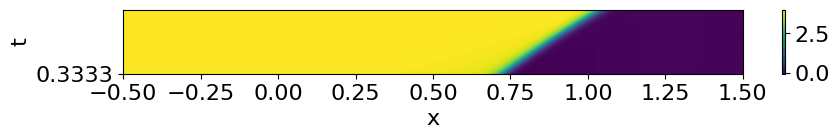

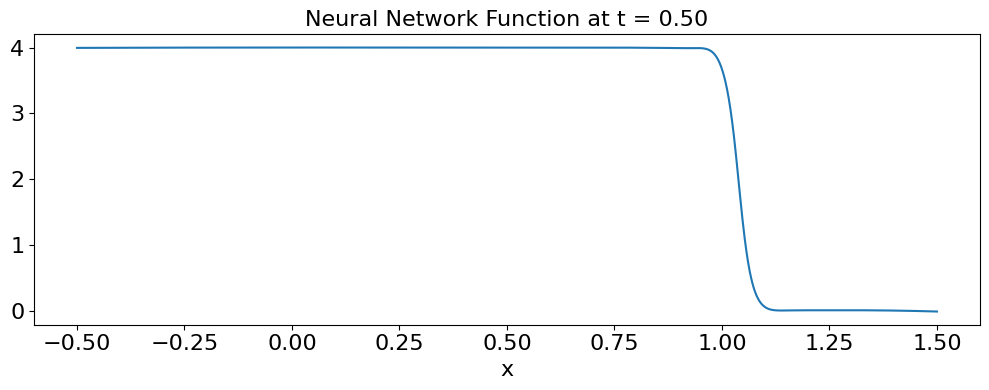

Grade 0, Iter 2100, loss_eqn: 0.232204, loss_eqn_from_kh: 0.229539, loss_l1: 0.660713, loss_ibc: 0.007750
Grade 0, Iter 2200, loss_eqn: 0.226280, loss_eqn_from_kh: 0.231940, loss_l1: 0.665091, loss_ibc: 0.007659
Grade 0, Iter 2300, loss_eqn: 0.222984, loss_eqn_from_kh: 0.223098, loss_l1: 0.659134, loss_ibc: 0.007336
Grade 0, Iter 2400, loss_eqn: 0.230335, loss_eqn_from_kh: 0.228606, loss_l1: 0.666570, loss_ibc: 0.007018
Grade 0, Iter 2500, loss_eqn: 0.227175, loss_eqn_from_kh: 0.231933, loss_l1: 0.666469, loss_ibc: 0.006735
Grade 0, Iter 2600, loss_eqn: 0.221616, loss_eqn_from_kh: 0.226879, loss_l1: 0.656447, loss_ibc: 0.006745
Grade 0, Iter 2700, loss_eqn: 0.225205, loss_eqn_from_kh: 0.221502, loss_l1: 0.659325, loss_ibc: 0.005990
Grade 0, Iter 2800, loss_eqn: 0.219335, loss_eqn_from_kh: 0.222229, loss_l1: 0.664024, loss_ibc: 0.005807
Grade 0, Iter 2900, loss_eqn: 0.218378, loss_eqn_from_kh: 0.218420, loss_l1: 0.662731, loss_ibc: 0.005277
Grade 0, Iter 3000, lambda_ic: 9.640469, lambd

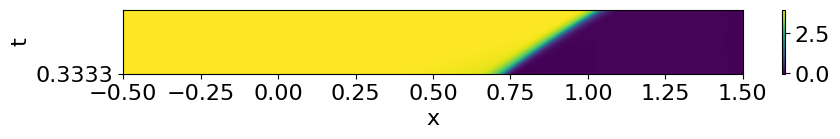

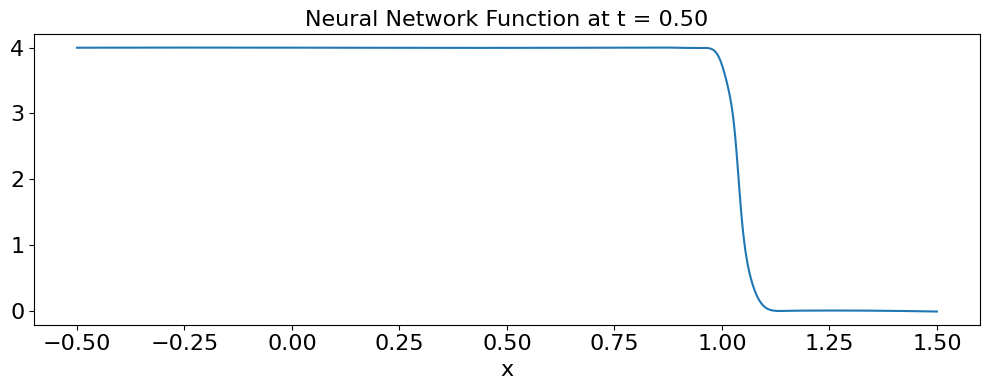

Grade 0, Iter 3100, loss_eqn: 0.213878, loss_eqn_from_kh: 0.213663, loss_l1: 0.660458, loss_ibc: 0.004497
Grade 0, Iter 3200, loss_eqn: 0.210555, loss_eqn_from_kh: 0.209862, loss_l1: 0.659252, loss_ibc: 0.004210
Grade 0, Iter 3300, loss_eqn: 0.208075, loss_eqn_from_kh: 0.207978, loss_l1: 0.656823, loss_ibc: 0.004001
Grade 0, Iter 3400, loss_eqn: 0.204051, loss_eqn_from_kh: 0.204424, loss_l1: 0.653989, loss_ibc: 0.003533
Grade 0, Iter 3500, loss_eqn: 0.199468, loss_eqn_from_kh: 0.199100, loss_l1: 0.648561, loss_ibc: 0.003338
Grade 0, Iter 3600, loss_eqn: 0.194947, loss_eqn_from_kh: 0.194786, loss_l1: 0.643940, loss_ibc: 0.003026
Grade 0, Iter 3700, loss_eqn: 0.190018, loss_eqn_from_kh: 0.191818, loss_l1: 0.636036, loss_ibc: 0.002873
Grade 0, Iter 3800, loss_eqn: 0.186201, loss_eqn_from_kh: 0.185623, loss_l1: 0.636849, loss_ibc: 0.002693
Grade 0, Iter 3900, loss_eqn: 0.183213, loss_eqn_from_kh: 0.181146, loss_l1: 0.633425, loss_ibc: 0.002459
Grade 0, Iter 4000, lambda_ic: 12.357890, lamb

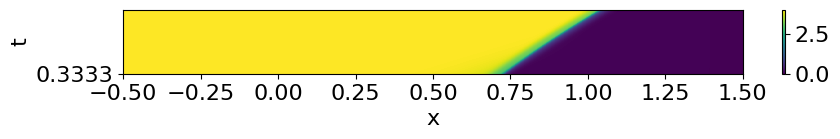

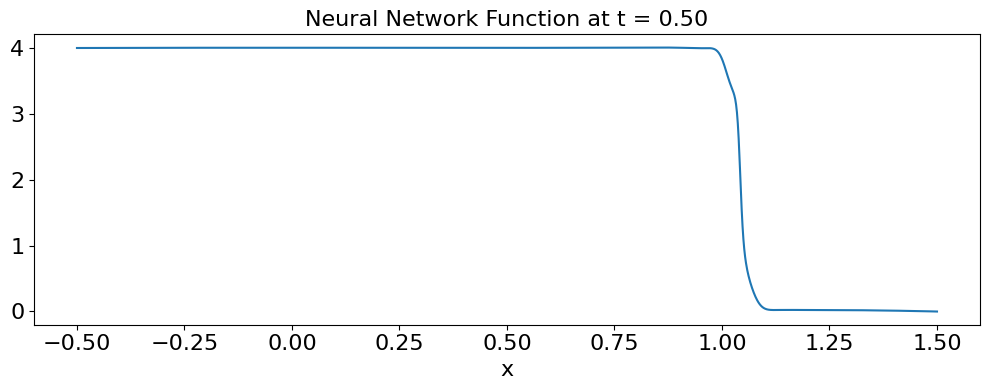

Grade 0, Iter 4100, loss_eqn: 0.176336, loss_eqn_from_kh: 0.177268, loss_l1: 0.634916, loss_ibc: 0.001961
Grade 0, Iter 4200, loss_eqn: 0.173852, loss_eqn_from_kh: 0.173135, loss_l1: 0.625573, loss_ibc: 0.001815
Grade 0, Iter 4300, loss_eqn: 0.170877, loss_eqn_from_kh: 0.170942, loss_l1: 0.621166, loss_ibc: 0.001754
Grade 0, Iter 4400, loss_eqn: 0.168568, loss_eqn_from_kh: 0.168440, loss_l1: 0.622037, loss_ibc: 0.001731
Grade 0, Iter 4500, loss_eqn: 0.167290, loss_eqn_from_kh: 0.166812, loss_l1: 0.619872, loss_ibc: 0.001733
Grade 0, Iter 4600, loss_eqn: 0.165930, loss_eqn_from_kh: 0.165557, loss_l1: 0.619117, loss_ibc: 0.001715
Grade 0, Iter 4700, loss_eqn: 0.164931, loss_eqn_from_kh: 0.164961, loss_l1: 0.620892, loss_ibc: 0.001724
Grade 0, Iter 4800, loss_eqn: 0.163913, loss_eqn_from_kh: 0.163868, loss_l1: 0.618483, loss_ibc: 0.001722
Grade 0, Iter 4900, loss_eqn: 0.163296, loss_eqn_from_kh: 0.163605, loss_l1: 0.617480, loss_ibc: 0.001714
Train time for stage1: 2021.736676 seconds

Pl

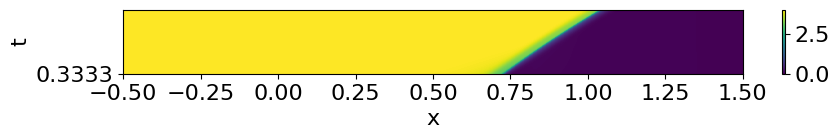

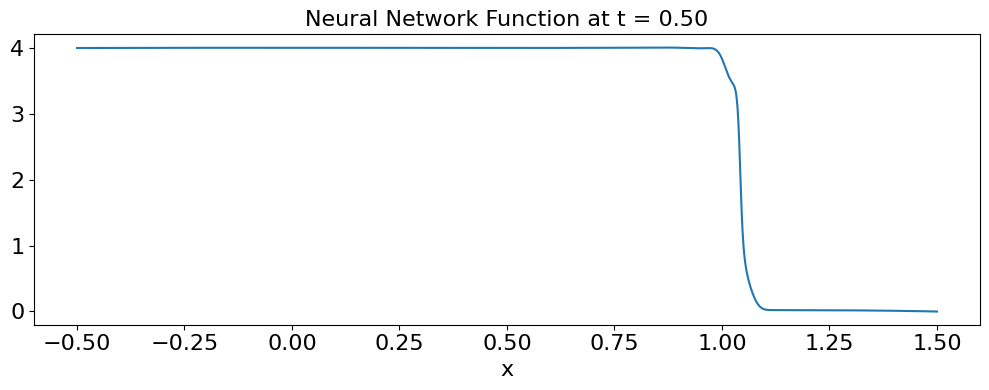


Plotting combined output across all segments from t=0 to total_t_max


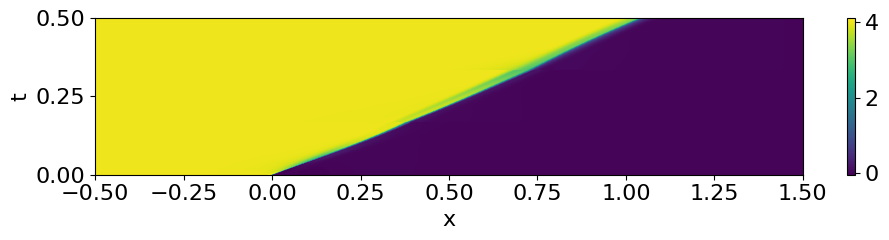

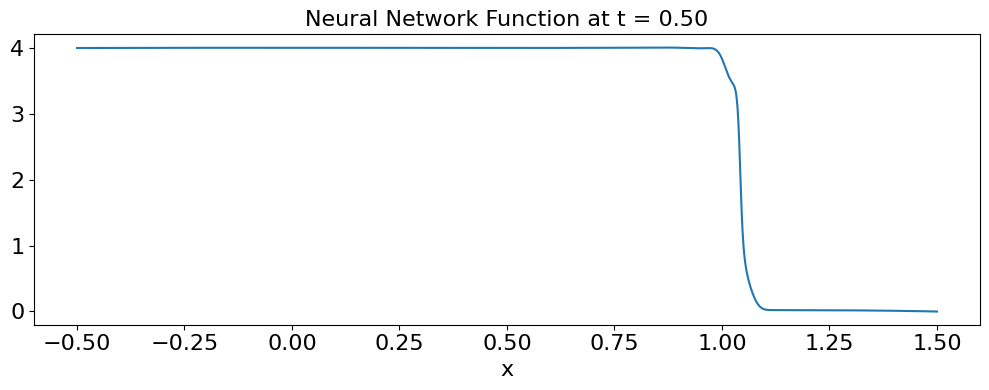

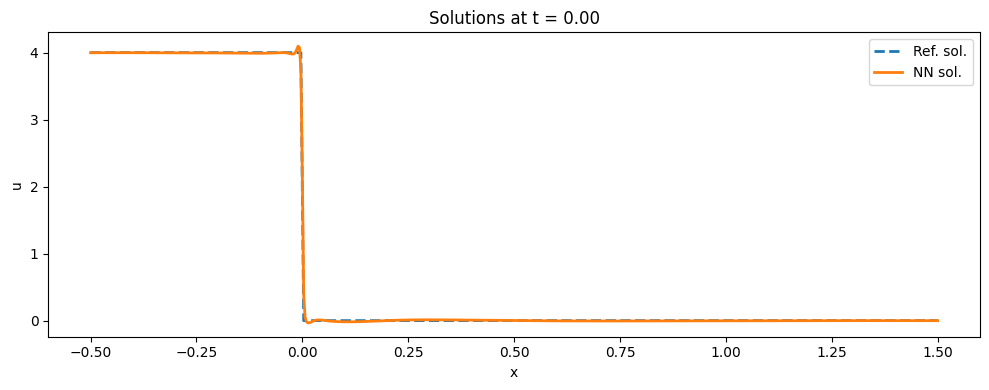

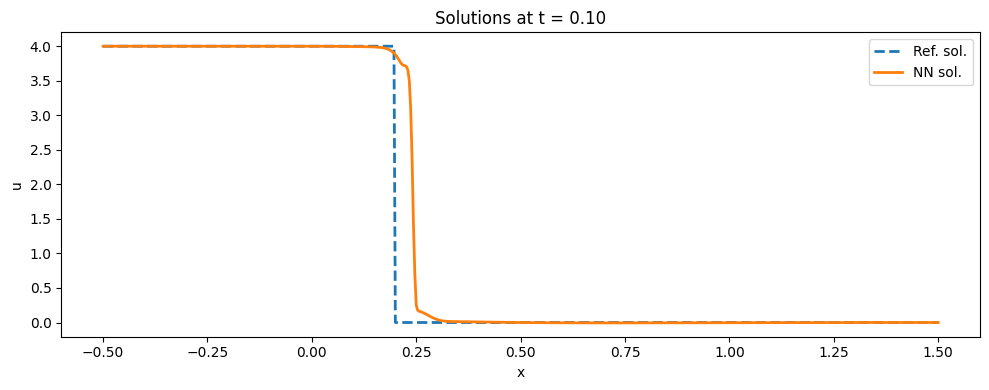

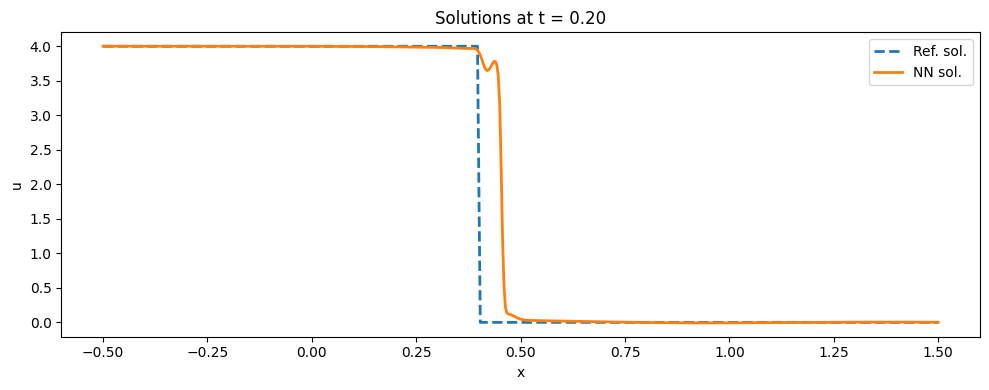

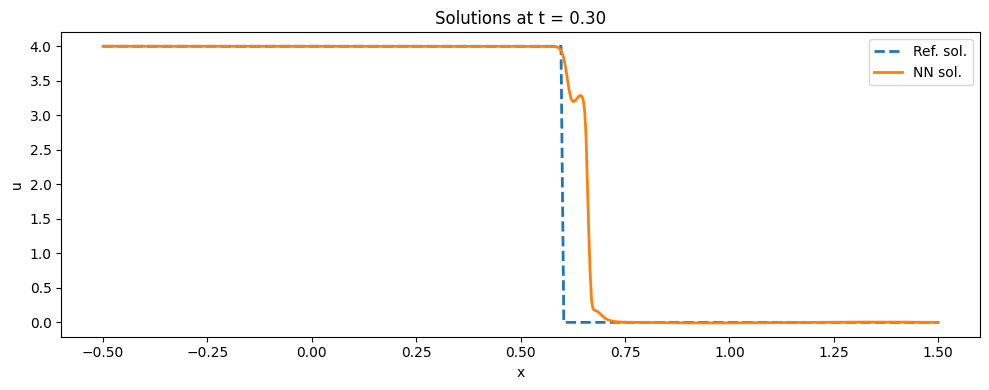

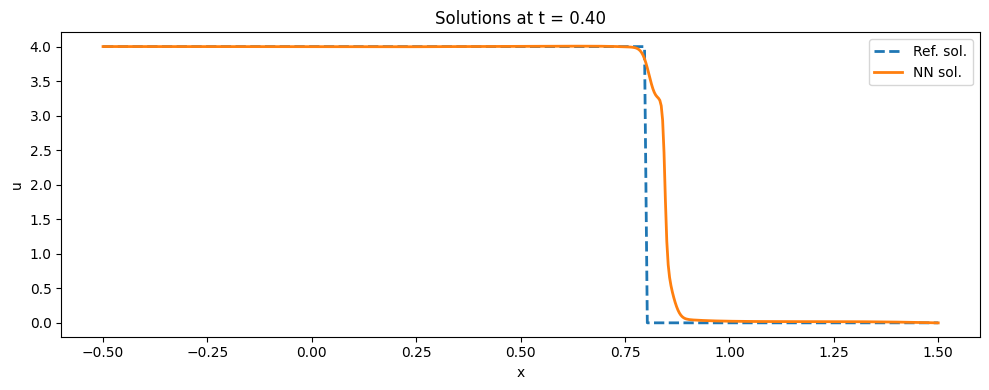

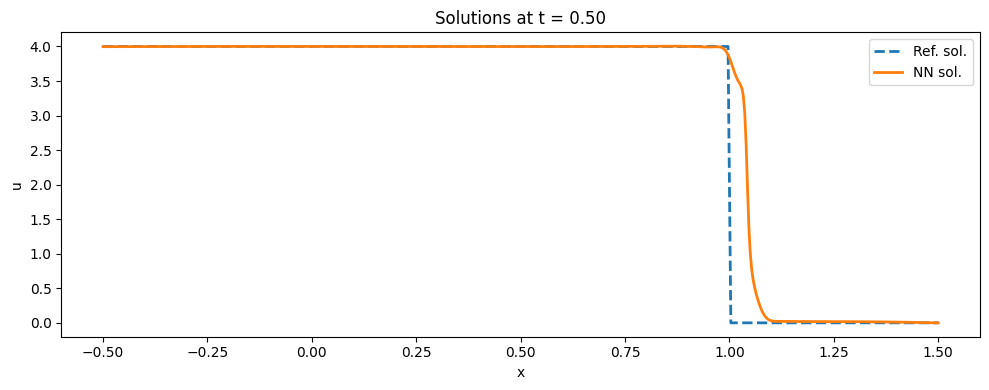

Error at T: 0.17931128378957528, Relative error at T: 0.029885213964929214
Space-time error: 0.09087674662123124, Space-time relative error: 0.04545440861587733


(np.float64(0.029885213964929214), np.float64(0.04545440861587733))

In [4]:
# This result is by 32*64 mesh
seq_trainer.train_seq()
plot_comparison_seperate_combined_u_theta(seq_trainer, u_ref=u_ref, x_min=-0.5, x_max=1.5, ts=[0.1*i for i in range(6)])
compute_errors_combined_u_theta(seq_trainer, u_ref=u_ref, x_min=-0.5, x_max=1.5, T=0.5)